## MTL Trajet: 04 Mode Purpose Land Use Joint Patterns (Flag 4)

### Dataset Overview
MTL Trajet 2016 mobility data with trip purpose, mode, timing, endpoints, trip metrics, and Montréal PUM 2050 destination land-use categories. User IDs distinguish participants, and the point tables provide speed profiles. The single-user case includes a repeated work corridor.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze differences in trajectory behaviour across transport modes, trip purposes, and urban spatial environments in the supplied multiple-user trajectories.

Role: Urban mobility and land-use analyst


Category: Transport mode, purpose, point-wise speed dynamics, and destination urban environment

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: For work and shopping separately, how do motor vehicle, public transit, and cycling differ in peak speed and continuous stable segments, and how does walking compare within shopping trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

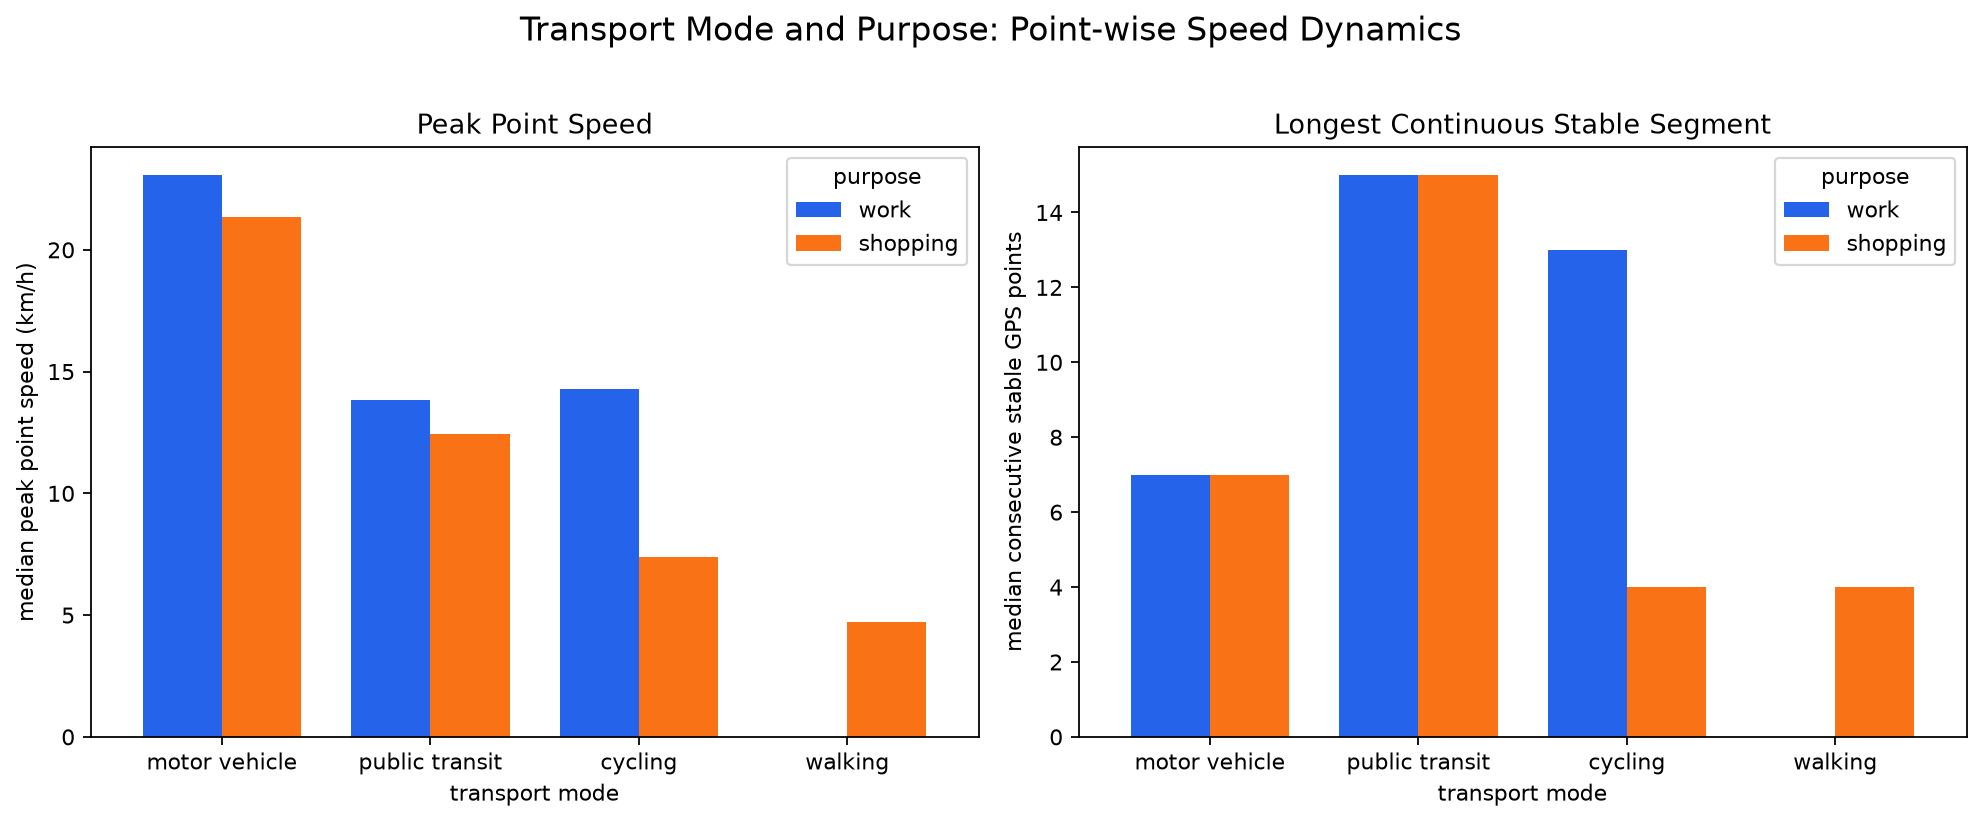

In [ ]:
df.groupby(['mode_group','purpose_group'])[['point_speed_peak_kmh','stable_speed_change_threshold_kmh','longest_stable_run_points']].median()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/mode_purpose_speed_dynamics.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mode_purpose_speed_dynamics",
  "insight": "Motor-vehicle trips reach the highest peak speeds, while public-transit trips maintain clearly longer continuous stable segments across work and shopping trips.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Transport Mode × Purpose: Speed Dynamics",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/mode_purpose_speed_dynamics.png"
  },
  "question": "For work and shopping separately, how do motor vehicle, public transit, and cycling differ in peak speed and continuous stable segments, and how does walking compare within shopping trips?",
  "code": "df.groupby(['mode_group','purpose_group'])[['point_speed_peak_kmh','stable_speed_change_threshold_kmh','longest_stable_run_points']].median()",
  "insight_type": "group_comparison",
  "evidence": "Across work and shopping trips, motor-vehicle trajectories have the highest peak point speeds. Public-transit trajectories have the longest continuous stable-speed segments, clearly exceeding motor vehicles as well as active modes.",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "transport_mode",
    "point_speed",
    "trajectory_id"
  ]
}

### **Question 2**: Are residential walking/cycling trips shorter and do they slow earlier near their destination than riverside-recreation cycling and motor-vehicle trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

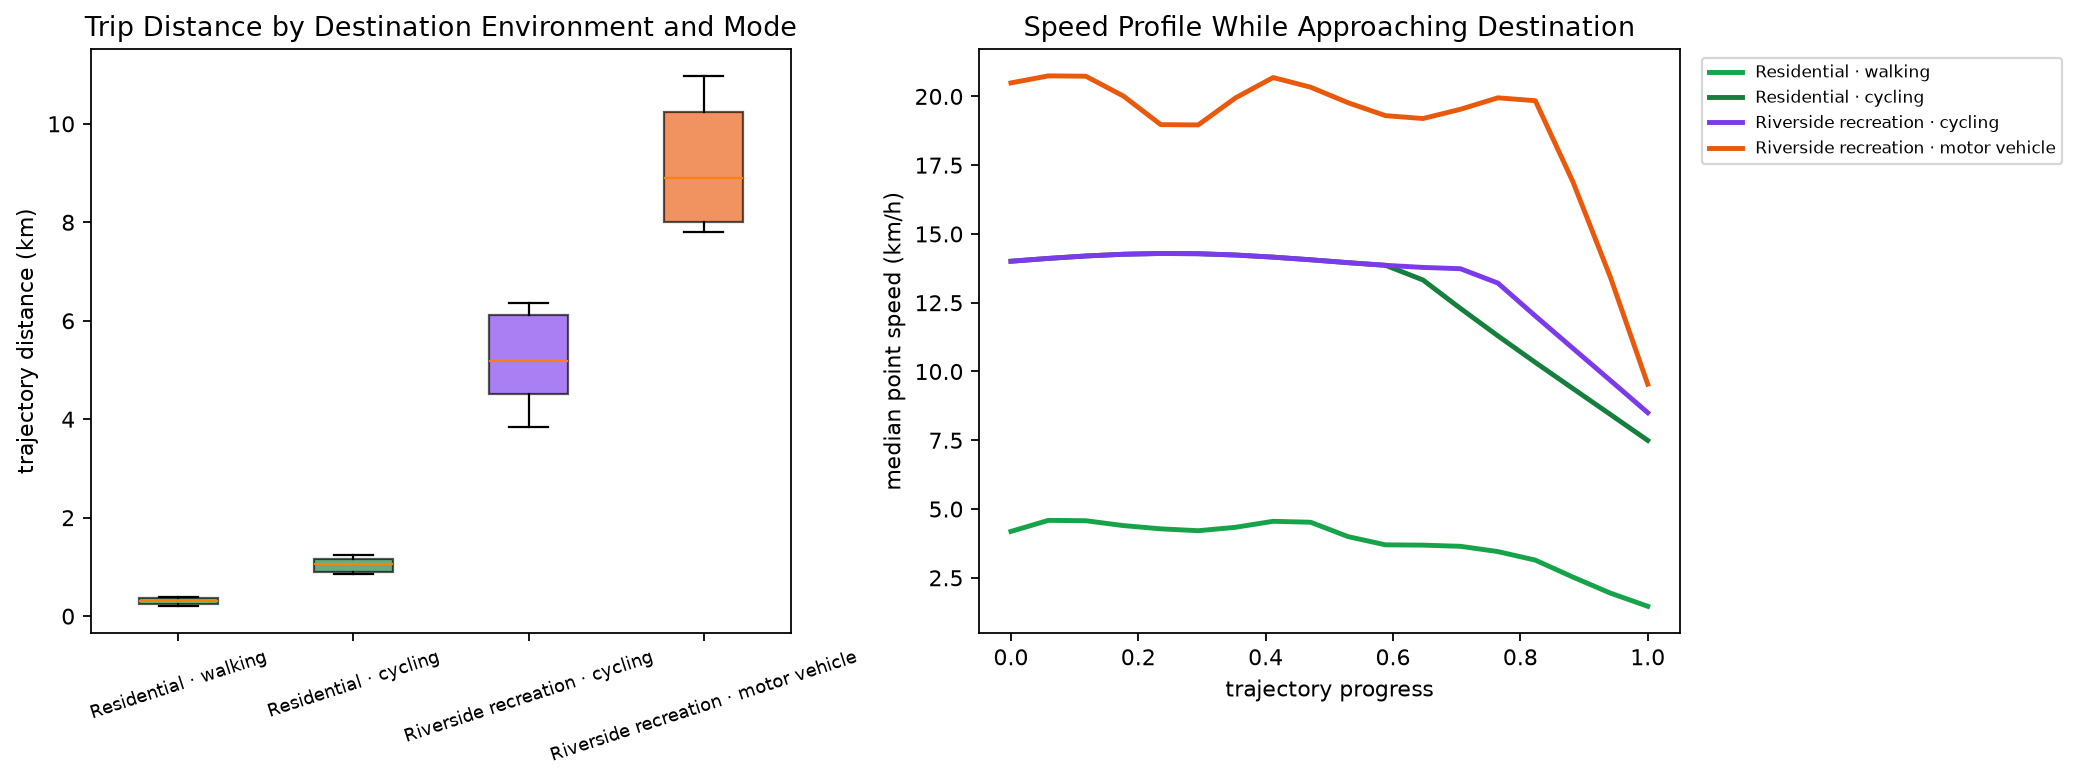

In [ ]:
df.groupby(['destination_land_use','mode_group'])[['distance_km','terminal_point_speed_kmh']].median()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/land_use_mode_trajectory_shape.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mode_land_use_trajectory_shape",
  "insight": "Active trips to residential destinations are short and begin slowing earlier near arrival than comparable riverside trips.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Transport Mode × Land-use: Trajectory Shape",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/land_use_mode_trajectory_shape.png"
  },
  "question": "Are residential walking/cycling trips shorter and do they slow earlier near their destination than riverside-recreation cycling and motor-vehicle trips?",
  "code": "df.groupby(['destination_land_use','mode_group'])[['distance_km','terminal_point_speed_kmh']].median()",
  "insight_type": "group_comparison",
  "evidence": "Residential walking and cycling trips cover shorter distances and begin their terminal slowdown earlier on normalized trajectory progress than comparable cycling and motor-vehicle trips ending in riverside recreation areas.",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "point_speed",
    "land_use_reference",
    "trajectory_id"
  ]
}

### **Question 3**: For the same shopping purpose, how do walking, cycling, public-transit, and motor-vehicle trips differ in distance, peak speed, speed variation, and continuous stable segments?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

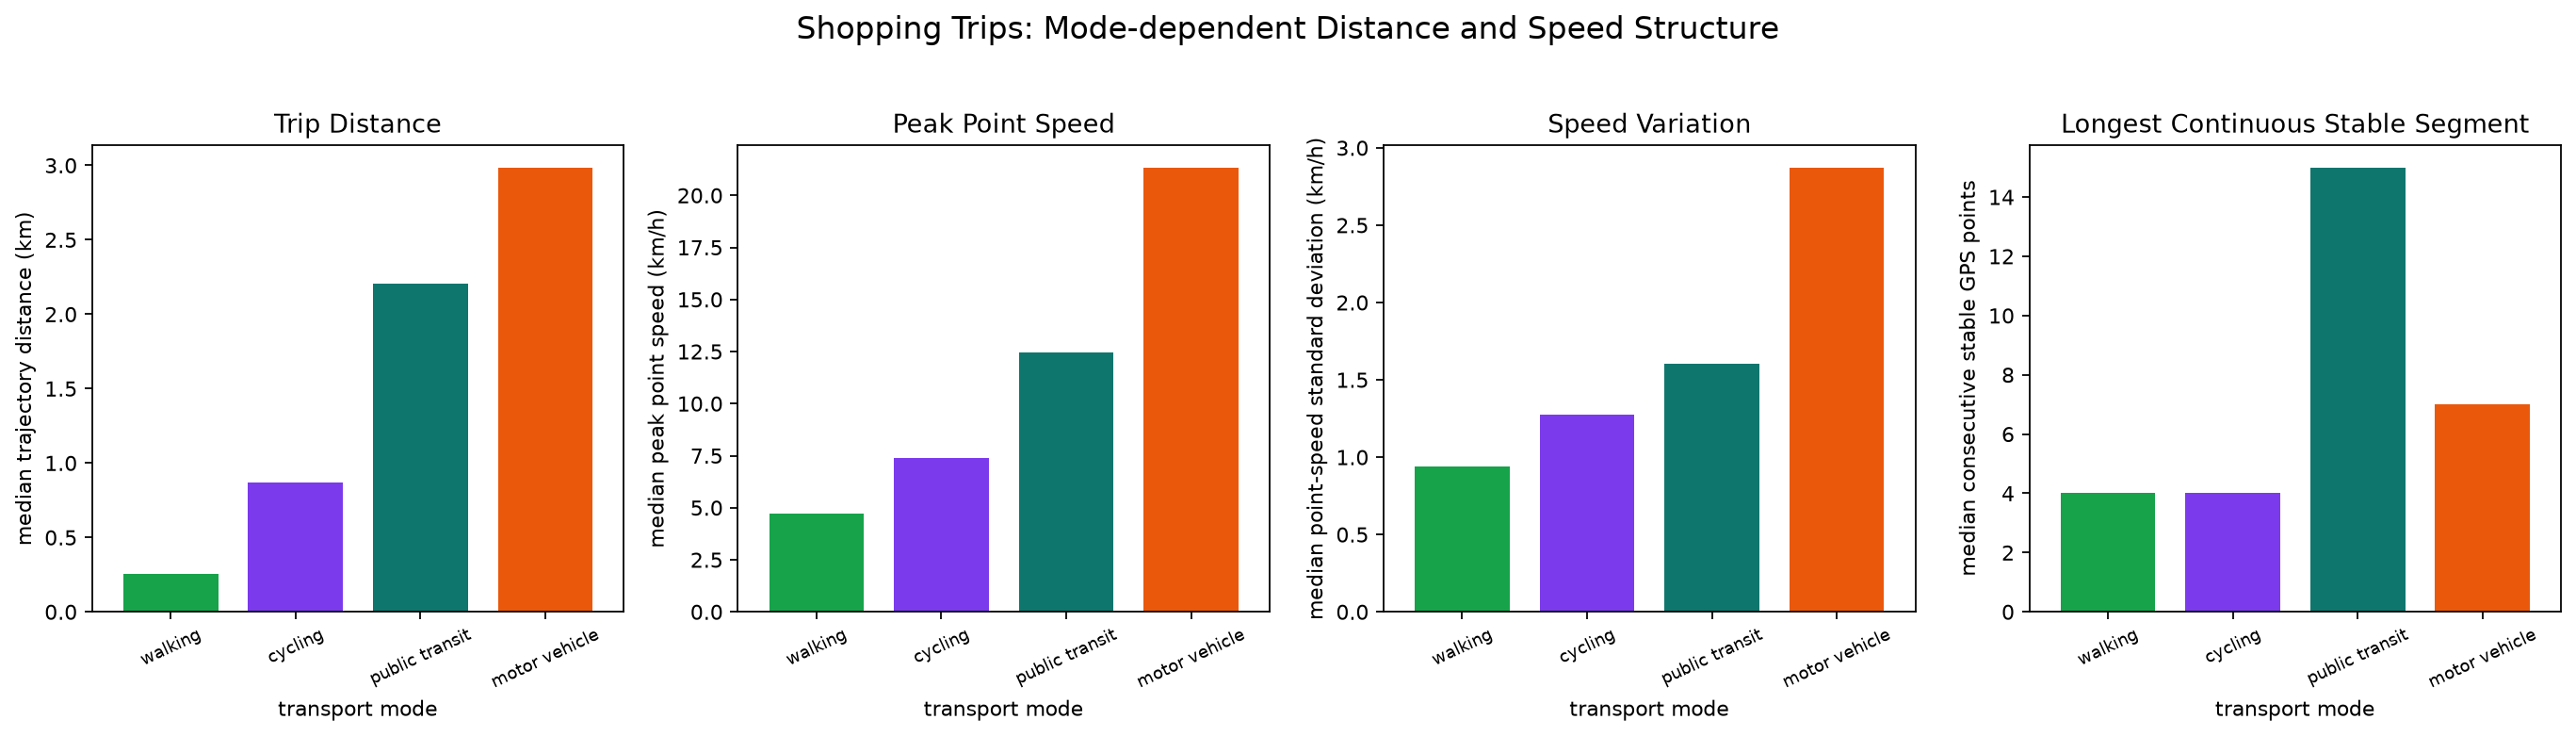

In [ ]:
df[df.purpose_group.eq('shopping')].groupby('mode_group')[['distance_km','point_speed_peak_kmh','point_speed_std_kmh','longest_stable_run_points']].median()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/purpose_mode_trip_structure.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "same_purpose_mode_difference",
  "insight": "For shopping trips, active modes are shorter and slower, while motorized modes sustain longer continuous movement segments.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Same Shopping Purpose, Different Modes",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_mode_trip_structure.png"
  },
  "question": "For the same shopping purpose, how do walking, cycling, public-transit, and motor-vehicle trips differ in distance, peak speed, speed variation, and continuous stable segments?",
  "code": "df[df.purpose_group.eq('shopping')].groupby('mode_group')[['distance_km','point_speed_peak_kmh','point_speed_std_kmh','longest_stable_run_points']].median()",
  "insight_type": "group_comparison",
  "evidence": "Within shopping trips, walking and cycling trajectories are shorter and slower than motor-vehicle and public-transit trajectories; the motorized modes also sustain longer continuous stable-speed segments.",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "transport_mode",
    "gps_position",
    "point_speed",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 4)

Across work and shopping trips, motor vehicles reach the highest peak speeds, while public transit maintains clearly longer continuous stable segments. Active trips to residential destinations are short and begin slowing earlier near arrival than comparable riverside trips. For shopping trips, active modes are shorter and slower, while motorized modes sustain longer continuous movement segments.